# MNIST Centroid-Based Feature Extraction

This project extracts simple geometric features from handwritten MNIST digits using a block-based centroid method.

Each 28×28 binary image is divided into a configurable grid. For every block, the centroid of the foreground (digit) pixels is calculated. The horizontal and vertical centroid coordinates are concatenated into a feature vector.

**This notebook focuses on feature extraction and visualization. It does not train a classification model.**

## 1. Imports and configuration

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.datasets import mnist

SEED = 42
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

# Change these values to experiment with different grid sizes.
GRID_ROWS = 4
GRID_COLS = 4
THRESHOLD = 127

if GRID_ROWS < 1 or GRID_COLS < 1:
    raise ValueError("GRID_ROWS and GRID_COLS must both be positive integers.")

I0000 00:00:1794257018.764581      51 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1794257034.573131      51 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


## 2. Load and binarize MNIST

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Training images: (60000, 28, 28)
Test images: (10000, 28, 28)


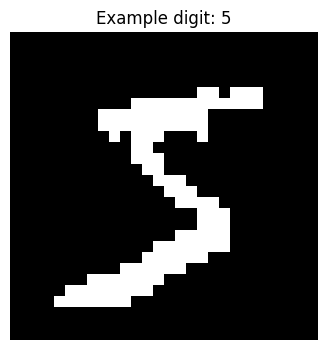

In [2]:
(X_train_raw, y_train), (X_test_raw, y_test) = mnist.load_data()

def binarize_images(images, threshold=127):
    """Convert grayscale images to binary arrays: 1 = foreground, 0 = background."""
    return (images > threshold).astype(np.uint8)

X_train = binarize_images(X_train_raw, THRESHOLD)
X_test = binarize_images(X_test_raw, THRESHOLD)

print("Training images:", X_train.shape)
print("Test images:", X_test.shape)

plt.figure(figsize=(4, 4))
plt.imshow(X_train[0], cmap="gray")
plt.title(f"Example digit: {y_train[0]}")
plt.axis("off")
plt.show()

## 3. Split an image into grid blocks

In [3]:
def split_into_blocks(image, rows, cols):
    """Split a 2D image into rows × cols blocks, including remainder pixels."""
    if image.ndim != 2:
        raise ValueError("Expected a 2D grayscale/binary image.")
    if not isinstance(rows, int) or not isinstance(cols, int) or rows < 1 or cols < 1:
        raise ValueError("rows and cols must be positive integers.")

    row_blocks = np.array_split(image, rows, axis=0)
    blocks = []
    for row_block in row_blocks:
        blocks.extend(np.array_split(row_block, cols, axis=1))
    return blocks

example_blocks = split_into_blocks(X_train[0], GRID_ROWS, GRID_COLS)
print(f"Created {len(example_blocks)} blocks.")
print("Block shapes:", [block.shape for block in example_blocks])

Created 16 blocks.
Block shapes: [(7, 7), (7, 7), (7, 7), (7, 7), (7, 7), (7, 7), (7, 7), (7, 7), (7, 7), (7, 7), (7, 7), (7, 7), (7, 7), (7, 7), (7, 7), (7, 7)]


## 4. Calculate the centroid of foreground pixels

In [5]:
def calculate_centroid(block):
    """Return (row_centroid, col_centroid) within a block.

    An empty block returns (0.0, 0.0), matching the original assignment's
    convention and avoiding division by zero.
    """
    foreground = np.argwhere(block == 1)
    if foreground.size == 0:
        return 0.0, 0.0

    row_centroid, col_centroid = foreground.mean(axis=0)
    return float(row_centroid), float(col_centroid)


# Quick example
print("Centroid of first block:", calculate_centroid(example_blocks[0]))

Centroid of first block: (0.0, 0.0)


## 5. Extract a feature vector from one image

In [6]:
def extract_features(image, rows=GRID_ROWS, cols=GRID_COLS):
    """Extract two centroid coordinates per block, in row-major order."""
    blocks = split_into_blocks(image, rows, cols)
    features = []
    for block in blocks:
        row_c, col_c = calculate_centroid(block)
        features.extend([row_c, col_c])
    return np.asarray(features, dtype=np.float32)

example_features = extract_features(X_train[0])
print("Feature vector:", example_features)
print("Feature vector length:", len(example_features))
print("Expected length:", 2 * GRID_ROWS * GRID_COLS)

Feature vector: [0.        0.        6.        5.        5.7       3.4       5.5
 0.5       0.        0.        2.        4.1666665 1.6363636 1.4545455
 0.        0.        0.        0.        5.6666665 5.6666665 3.3214285
 2.607143  0.        0.        2.6       5.2       1.4761904 2.857143
 0.        0.5       0.        0.       ]
Feature vector length: 32
Expected length: 32


## 6. Visualize grid and block centroids

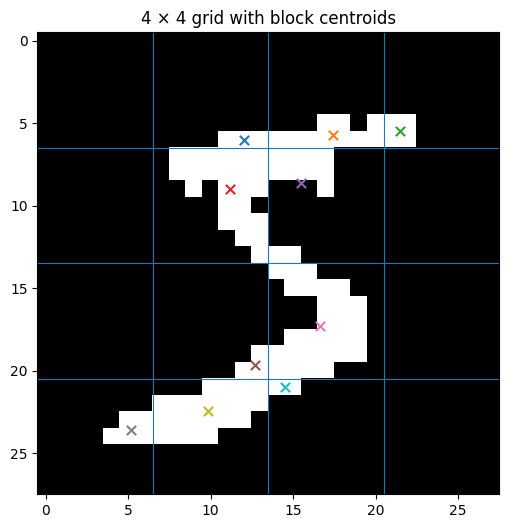

In [7]:
def visualize_centroids(image, rows=GRID_ROWS, cols=GRID_COLS):
    """Show the binary digit, grid boundaries, and non-empty block centroids."""
    height, width = image.shape
    row_edges = np.linspace(0, height, rows + 1)
    col_edges = np.linspace(0, width, cols + 1)

    fig, ax = plt.subplots(figsize=(6, 6))
    ax.imshow(image, cmap="gray", vmin=0, vmax=1)

    for edge in row_edges:
        ax.axhline(edge - 0.5, linewidth=0.8)
    for edge in col_edges:
        ax.axvline(edge - 0.5, linewidth=0.8)

    row_blocks = np.array_split(image, rows, axis=0)
    for r, row_block in enumerate(row_blocks):
        col_blocks = np.array_split(row_block, cols, axis=1)
        row_start = int(round(row_edges[r]))
        for c, block in enumerate(col_blocks):
            if np.any(block == 1):
                row_c, col_c = calculate_centroid(block)
                global_row = row_start + row_c
                col_start = int(round(col_edges[c]))
                global_col = col_start + col_c
                ax.scatter(global_col, global_row, marker="x", s=45)

    ax.set_title(f"{rows} × {cols} grid with block centroids")
    ax.set_xlim(-0.5, width - 0.5)
    ax.set_ylim(height - 0.5, -0.5)
    plt.show()

visualize_centroids(X_train[0])

## 7. Extract features for training and test sets

In [8]:
def extract_dataset_features(images, rows=GRID_ROWS, cols=GRID_COLS):
    """Extract feature vectors for a collection of images."""
    return np.vstack([
        extract_features(image, rows, cols)
        for image in images
    ])

X_train_features = extract_dataset_features(X_train, GRID_ROWS, GRID_COLS)
X_test_features = extract_dataset_features(X_test, GRID_ROWS, GRID_COLS)

print("Training feature matrix:", X_train_features.shape)
print("Test feature matrix:", X_test_features.shape)
print("Training labels:", y_train.shape)
print("Test labels:", y_test.shape)

Training feature matrix: (60000, 32)
Test feature matrix: (10000, 32)
Training labels: (60000,)
Test labels: (10000,)


## 8. Inspect sample feature vectors

In [9]:
for index in range(5):
    print(f"Image {index} | Label: {y_train[index]}")
    print("Features:", X_train_features[index])
    print("-" * 60)

Image 0 | Label: 5
Features: [0.        0.        6.        5.        5.7       3.4       5.5
 0.5       0.        0.        2.        4.1666665 1.6363636 1.4545455
 0.        0.        0.        0.        5.6666665 5.6666665 3.3214285
 2.607143  0.        0.        2.6       5.2       1.4761904 2.857143
 0.        0.5       0.        0.       ]
------------------------------------------------------------
Image 1 | Label: 0
Features: [0.         0.         0.         0.         5.214286   2.7857144
 0.         0.         0.         0.         3.2        3.85
 1.6        3.45       4.         0.33333334 0.         0.
 3.1764705  1.         3.8235295  3.8235295  0.8        0.4
 0.         0.         0.8947368  3.         0.25       0.75
 0.         0.        ]
------------------------------------------------------------
Image 2 | Label: 4
Features: [0.        0.        0.        0.        0.        0.        5.5
 0.        3.2307692 4.230769  0.        0.        3.7142856 5.142857
 0.5  

## 9. Save extracted features

In [10]:
feature_columns = [
    f"block_{block_index + 1}_{coordinate}"
    for block_index in range(GRID_ROWS * GRID_COLS)
    for coordinate in ("row_centroid", "col_centroid")
]

train_df = pd.DataFrame(X_train_features, columns=feature_columns)
train_df["label"] = y_train
train_df.to_csv("mnist_centroid_features_train.csv", index=False)

test_df = pd.DataFrame(X_test_features, columns=feature_columns)
test_df["label"] = y_test
test_df.to_csv("mnist_centroid_features_test.csv", index=False)

print("Saved training and test feature CSV files.")

Saved training and test feature CSV files.
